# 머신러닝 기반 음성분류
-실습조교 김류하
## [**Goal**]

- **알게 될 것:** 음성을 특징으로 바꾸고, 머신러닝이 종류를 맞히는 과정.
- **해볼 것:** 한 음성의 STFT·MFCC·BFCC·GFCC 비교, i-vector 그림 보기, 분류기 성능 비교.
- **달성 목표:** 특징과 분류기를 바꾸어 결과를 비교하고, 학습에서 제외된 음성을 들으며 예측을 확인한다.

이 노트북은 `train.csv`와 학습 음성만 사용합니다. 먼저 아래 데이터 ZIP을 Colab에 올려 주세요.


In [1]:
%pip -q install soundfile

## 학습 음성 업로드

함께 제공한 `train_audio_bundle.zip`을 먼저 내려받은 뒤 아래 셀에서 선택하세요. ZIP을 Google Drive에 올려 두고 써도 됩니다. 음성·라벨 데이터가 공개 가능한지 확인한 뒤 공유하세요.

In [2]:
from google.colab import files
from pathlib import Path
import zipfile

uploaded = files.upload()  # train_audio_bundle.zip 선택
zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
if len(zip_names) != 1:
    raise ValueError("train_audio_bundle.zip 파일 하나를 업로드해 주세요.")

WORK_DIR = Path("/content/asvspoof_train")
WORK_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_names[0]) as archive:
    bad_member = next((name for name in archive.namelist() if Path(name).is_absolute() or ".." in Path(name).parts), None)
    if bad_member:
        raise ValueError(f"안전하지 않은 ZIP 경로: {bad_member}")
    archive.extractall(WORK_DIR)

csv_files = list(WORK_DIR.rglob("train.csv"))
if len(csv_files) != 1:
    raise FileNotFoundError("ZIP 안에서 train.csv를 하나 찾을 수 없습니다.")
DATASET_DIR = csv_files[0].parent
print("데이터 위치:", DATASET_DIR)
print("train.csv:", csv_files[0])

Saving train_audio_bundle.zip to train_audio_bundle (1).zip
데이터 위치: /content/asvspoof_train/dataset
train.csv: /content/asvspoof_train/dataset/train.csv


In [3]:
import csv
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from scipy.fft import dct

train_df = pd.read_csv(DATASET_DIR / "train.csv")
required = {"path", "label", "speaker_id"}
if not required.issubset(train_df.columns):
    raise ValueError(f"train.csv에 필요한 열이 없습니다: {sorted(required - set(train_df.columns))}")
audio_paths = [DATASET_DIR / relative for relative in train_df["path"]]
missing = [str(path) for path in audio_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f"학습 음성 {len(missing)}개를 찾지 못했습니다. 예: {missing[:3]}")

print(f"학습 음성 {len(train_df)}개 / 화자 {train_df['speaker_id'].nunique()}명")
display(train_df["label"].value_counts().rename_axis("label").to_frame("count"))

학습 음성 120개 / 화자 10명


,count
label,
original,30
sovits,30
voice_conversion,30
TTS,30


## 한 음성으로 특징 비교

왼쪽 위 STFT는 시간에 따른 주파수 에너지, 나머지는 같은 음성의 MFCC·BFCC·GFCC 켑스트럼입니다. `SAMPLE_INDEX`를 바꾸면 모든 그림과 재생 음성이 함께 바뀝니다.

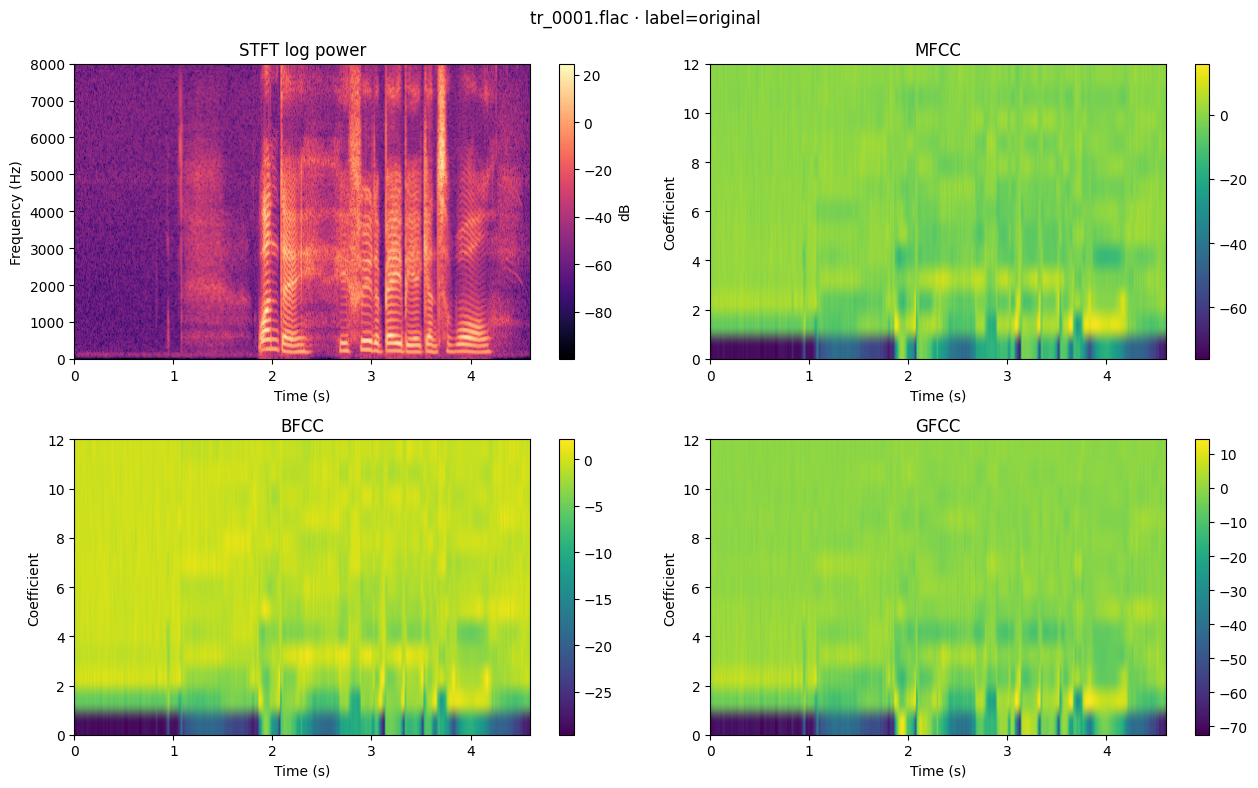

In [4]:
SR = 16000
WIN, HOP, N_FFT, N_FILTERS, N_CEPS = 400, 160, 512, 40, 13
PREEMPH = 0.97
FREQS = np.linspace(0.0, SR / 2, N_FFT // 2 + 1)
WINDOW = np.hamming(WIN)

def triangles(edges):
    lo, mid, hi = edges[:-2, None], edges[1:-1, None], edges[2:, None]
    return np.maximum(0.0, np.minimum((FREQS - lo) / (mid - lo), (hi - FREQS) / (hi - mid)))

def make_filters():
    hz2mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
    mel2hz = lambda m: 700.0 * (10.0 ** (m / 2595.0) - 1.0)
    mel = triangles(mel2hz(np.linspace(hz2mel(0), hz2mel(SR / 2), N_FILTERS + 2)))

    hz2bark = lambda f: 6.0 * np.arcsinh(f / 600.0)
    bark2hz = lambda b: 600.0 * np.sinh(b / 6.0)
    bark = triangles(bark2hz(np.linspace(hz2bark(0), hz2bark(SR / 2), N_FILTERS + 2)))
    w2 = (2 * np.pi * (bark @ FREQS / np.maximum(bark.sum(axis=1), 1e-12))) ** 2
    loudness = (w2 + 56.8e6) * w2 ** 2 / ((w2 + 6.3e6) ** 2 * (w2 + 0.38e9))
    bark *= loudness[:, None]

    erb = lambda f: 24.7 * (4.37 * f / 1000.0 + 1.0)
    hz2erb = lambda f: 21.4 * np.log10(4.37 * f / 1000.0 + 1.0)
    erb2hz = lambda e: (10.0 ** (e / 21.4) - 1.0) * 1000.0 / 4.37
    centers = erb2hz(np.linspace(hz2erb(50.0), hz2erb(SR / 2), N_FILTERS))
    bandwidth = 1.019 * erb(centers)[:, None]
    gamma = (1.0 + ((FREQS - centers[:, None]) / bandwidth) ** 2) ** -2.0
    return {"mfcc": mel, "bfcc": bark, "gfcc": gamma}

FILTERS = make_filters()

def load_audio(path):
    signal, sr = sf.read(path, dtype="float32", always_2d=False)
    if signal.ndim > 1:
        signal = signal.mean(axis=1)
    if sr != SR:
        length = int(round(len(signal) * SR / sr))
        signal = np.interp(np.linspace(0, len(signal), length, endpoint=False), np.arange(len(signal)), signal).astype(np.float32)
    return signal

def power_spectrogram(signal):
    signal = np.append(signal[0], signal[1:] - PREEMPH * signal[:-1])
    if len(signal) < WIN:
        signal = np.pad(signal, (0, WIN - len(signal)))
    frames = np.lib.stride_tricks.sliding_window_view(signal, WIN)[::HOP]
    return np.abs(np.fft.rfft(frames * WINDOW, N_FFT)) ** 2

def cepstra(power, kind):
    energy = power @ FILTERS[kind].T + 1e-10
    compressed = np.log(energy ** 0.33) if kind == "bfcc" else np.log(energy)
    return dct(compressed, type=2, norm="ortho", axis=1)[:, :N_CEPS]

def delta(coefficients, width=2):
    padded = np.pad(coefficients, ((width, width), (0, 0)), mode="edge")
    n = len(coefficients)
    weights = np.arange(1, width + 1)
    numerator = sum(w * (padded[width + w:width + w + n] - padded[width - w:width - w + n]) for w in weights)
    return numerator / (2 * (weights ** 2).sum())

def summary(power, kind):
    c = cepstra(power, kind)
    d = delta(c)
    return np.concatenate([c.mean(0), c.std(0), d.mean(0), d.std(0)])

SAMPLE_INDEX = 0
sample_audio = load_audio(audio_paths[SAMPLE_INDEX])
sample_power = power_spectrogram(sample_audio)
display(Audio(sample_audio, rate=SR))
duration = len(sample_audio) / SR

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
image = axes[0, 0].imshow(10 * np.log10(sample_power.T + 1e-10), origin="lower", aspect="auto", extent=[0, duration, 0, SR / 2], cmap="magma")
axes[0, 0].set(ylim=(0, 8000), title="STFT log power", xlabel="Time (s)", ylabel="Frequency (Hz)")
fig.colorbar(image, ax=axes[0, 0], label="dB")
for ax, name in zip(axes.flat[1:], ("mfcc", "bfcc", "gfcc")):
    values = cepstra(sample_power, name)
    image = ax.imshow(values.T, origin="lower", aspect="auto", extent=[0, duration, 0, N_CEPS - 1], cmap="viridis")
    ax.set(title=name.upper(), xlabel="Time (s)", ylabel="Coefficient")
    fig.colorbar(image, ax=ax)
fig.suptitle(f"{audio_paths[SAMPLE_INDEX].name} · label={train_df.iloc[SAMPLE_INDEX]['label']}")
fig.tight_layout()
plt.show()

## 특징 전체 계산

MFCC/BFCC/GFCC는 계수와 델타의 평균·표준편차(각 52차원), STFT는 로그 파워의 평균·표준편차(514차원)로 요약합니다.

In [5]:
AUDIO_SIGNALS = [load_audio(path) for path in audio_paths]
FEATURES = {name: [] for name in ("mfcc", "bfcc", "gfcc", "stft")}
for index, signal in enumerate(AUDIO_SIGNALS):
    power = power_spectrogram(signal)
    for name in ("mfcc", "bfcc", "gfcc"):
        FEATURES[name].append(summary(power, name))
    log_power = np.log(power + 1e-10)
    FEATURES["stft"].append(np.r_[log_power.mean(axis=0), log_power.std(axis=0)])
    if (index + 1) % 30 == 0:
        print(f"{index + 1}/{len(AUDIO_SIGNALS)}")
FEATURES = {name: np.asarray(values, dtype=np.float32) for name, values in FEATURES.items()}
display(pd.DataFrame({name: [matrix.shape[1]] for name, matrix in FEATURES.items()}, index=["dimension"]).T.rename(columns={0: "dimensions"}))

30/120
60/120
90/120
120/120


,dimension
mfcc,52
bfcc,52
gfcc,52
stft,514


## i-vector와 분류기

**i-vector**는 GMM-UBM의 통계량을 저차원 화자 벡터로 요약하는 전통 방식입니다. 아래는 작은 학습 데이터에서 동작하도록 PCA로 T 공간을 근사한 교육용 구현이며, 정식 EM/PLDA 시스템은 아닙니다. **Random Forest**는 여러 트리를 결합하고, **SVM**은 클래스 사이 여백을 찾으며, **XGBoost**는 앞선 트리의 오차를 보완하도록 트리를 순차 학습합니다.

In [6]:
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

class PCAIVector:
    def __init__(self, mixtures=8, dimensions=8, random_state=42):
        self.mixtures, self.dimensions, self.random_state = mixtures, dimensions, random_state

    @staticmethod
    def frames(signal):
        return cepstra(power_spectrogram(signal), "mfcc")[:, 1:].astype(np.float64)

    def stats(self, signal):
        frames = self.frames(signal)
        posterior = self.ubm.predict_proba(frames)
        counts = posterior.sum(axis=0)
        centered = frames[:, None, :] - self.ubm.means_[None, :, :]
        first = np.einsum("tk,tkd->kd", posterior, centered)
        return counts, first

    def fit(self, signals, speakers):
        sampled = []
        for signal in signals:
            frames = self.frames(signal)
            sampled.append(frames[np.linspace(0, len(frames) - 1, min(120, len(frames))).astype(int)])
        self.ubm = GaussianMixture(n_components=self.mixtures, covariance_type="diag", reg_covar=1e-4, max_iter=30, n_init=1, random_state=self.random_state).fit(np.concatenate(sampled))
        pooled = {}
        for signal, speaker in zip(signals, speakers):
            counts, first = self.stats(signal)
            if speaker not in pooled:
                pooled[speaker] = [np.zeros_like(counts), np.zeros_like(first)]
            pooled[speaker][0] += counts
            pooled[speaker][1] += first
        speaker_vectors = np.stack([(first / np.maximum(counts[:, None], 1e-6)).ravel() for counts, first in pooled.values()])
        rank = min(self.dimensions, len(speaker_vectors) - 1, speaker_vectors.shape[1])
        if rank < 1:
            raise ValueError("i-vector 추정에는 최소 2명의 화자가 필요합니다.")
        pca = PCA(n_components=rank, svd_solver="full").fit(speaker_vectors)
        loading = pca.components_.T * np.sqrt(np.maximum(pca.explained_variance_, 1e-6))
        self.loading = loading.reshape(self.mixtures, -1, rank)
        self.inverse_variance = 1.0 / np.maximum(self.ubm.covariances_, 1e-5)
        self.embedding_dim = rank
        return self

    def transform(self, signals):
        vectors = []
        rank = self.embedding_dim
        for signal in signals:
            counts, first = self.stats(signal)
            precision = np.eye(rank) + np.einsum("c,cdr,cds,cd->rs", counts, self.loading, self.loading, self.inverse_variance, optimize=True)
            natural = np.einsum("cdr,cd,cd->r", self.loading, first, self.inverse_variance, optimize=True)
            vector = np.linalg.solve(precision, natural)
            vectors.append(vector / max(np.linalg.norm(vector), 1e-10))
        return np.asarray(vectors, dtype=np.float32)

print("i-vector extractor 준비 완료")

i-vector extractor 준비 완료


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

encoder = LabelEncoder()
y = encoder.fit_transform(train_df["label"])
speakers = train_df["speaker_id"].to_numpy()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def make_models():
    models = {
        "Random Forest": lambda: RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1),
        "SVM": lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")),
    }
    if XGBOOST_AVAILABLE:
        models["XGBoost"] = lambda: XGBClassifier(objective="multi:softprob", num_class=len(encoder.classes_), eval_metric="mlogloss", n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42, n_jobs=-1)
    return models

print("사용 분류기:", list(make_models()))
if not XGBOOST_AVAILABLE:
    print("XGBoost 설치: %pip install xgboost 실행 후 이 셀부터 다시 실행하세요.")

사용 분류기: ['Random Forest', 'SVM', 'XGBoost']


## 화자별 교차검증 결과

같은 화자의 음성이 학습 fold와 평가 fold에 섞이지 않도록 나눕니다. i-vector 추출기도 각 fold의 학습 화자만으로 다시 학습합니다.

In [8]:
rows, OOF = [], {}
for feature_name, matrix in FEATURES.items():
    for model_name, build_model in make_models().items():
        predicted = cross_val_predict(build_model(), matrix, y, groups=speakers, cv=cv, n_jobs=1)
        OOF[(feature_name, model_name)] = predicted
        rows.append({"feature": feature_name.upper(), "model": model_name, "accuracy": accuracy_score(y, predicted), "macro-F1": f1_score(y, predicted, average="macro")})
        print("완료:", feature_name, model_name)

ivector_oof = {name: np.empty_like(y) for name in make_models()}
for fold, (train_idx, held_idx) in enumerate(cv.split(FEATURES["mfcc"], y, speakers), start=1):
    extractor = PCAIVector().fit([AUDIO_SIGNALS[i] for i in train_idx], speakers[train_idx])
    train_vec = extractor.transform([AUDIO_SIGNALS[i] for i in train_idx])
    held_vec = extractor.transform([AUDIO_SIGNALS[i] for i in held_idx])
    for name, build_model in make_models().items():
        ivector_oof[name][held_idx] = build_model().fit(train_vec, y[train_idx]).predict(held_vec)
    print(f"i-vector fold {fold}/5")

for name, predicted in ivector_oof.items():
    OOF[("ivector", name)] = predicted
    rows.append({"feature": "I-VECTOR", "model": name, "accuracy": accuracy_score(y, predicted), "macro-F1": f1_score(y, predicted, average="macro")})
results = pd.DataFrame(rows).sort_values("macro-F1", ascending=False).reset_index(drop=True)
display(results.round(3))

완료: mfcc Random Forest
완료: mfcc SVM
완료: mfcc XGBoost
완료: bfcc Random Forest
완료: bfcc SVM
완료: bfcc XGBoost
완료: gfcc Random Forest
완료: gfcc SVM
완료: gfcc XGBoost
완료: stft Random Forest
완료: stft SVM
완료: stft XGBoost
i-vector fold 1/5
i-vector fold 2/5


/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


i-vector fold 3/5
i-vector fold 4/5
i-vector fold 5/5


,feature,model,accuracy,macro-F1
0,MFCC,Random Forest,0.858,0.859
1,BFCC,SVM,0.808,0.809
2,BFCC,Random Forest,0.800,0.797
3,GFCC,XGBoost,0.792,0.794
4,STFT,XGBoost,0.792,0.793
5,GFCC,Random Forest,0.783,0.786
6,MFCC,SVM,0.767,0.768
7,STFT,SVM,0.758,0.761
8,STFT,Random Forest,0.758,0.758
9,MFCC,XGBoost,0.758,0.757


## i-vector t-SNE

점 하나가 학습 음성 하나입니다. 색은 실제 라벨입니다. t-SNE는 가까운 벡터를 보기 위한 시각화로, 점수나 일반화 성능을 뜻하지 않습니다.

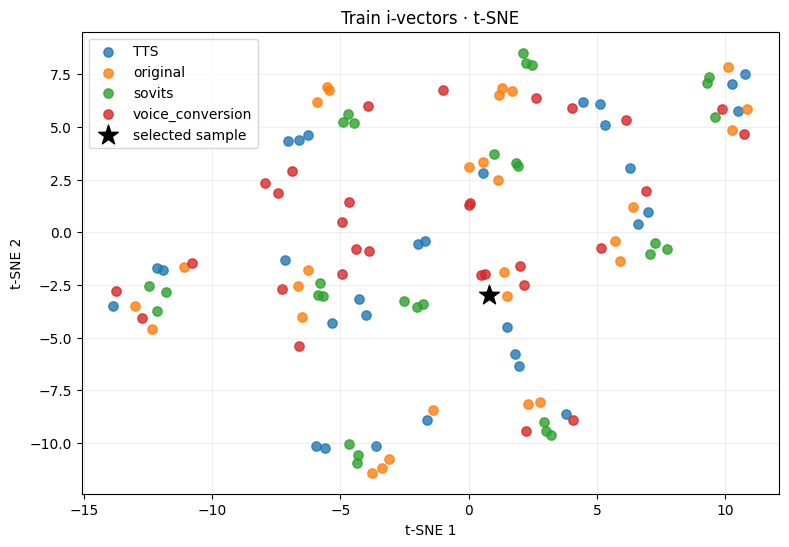

i-vector shape: (120, 8) → t-SNE: (120, 2)


In [9]:
from sklearn.manifold import TSNE

ivectors = PCAIVector().fit(AUDIO_SIGNALS, speakers).transform(AUDIO_SIGNALS)
perplexity = min(20, len(ivectors) - 1)
xy = TSNE(n_components=2, perplexity=perplexity, init="pca", learning_rate="auto", random_state=42).fit_transform(ivectors)
fig, ax = plt.subplots(figsize=(9, 6))
for index, label in enumerate(sorted(train_df["label"].unique())):
    mask = train_df["label"].to_numpy() == label
    ax.scatter(xy[mask, 0], xy[mask, 1], label=label, alpha=0.8, s=45)
ax.scatter(xy[SAMPLE_INDEX, 0], xy[SAMPLE_INDEX, 1], marker="*", s=220, color="black", label="selected sample")
ax.set(title="Train i-vectors · t-SNE", xlabel="t-SNE 1", ylabel="t-SNE 2")
ax.legend()
ax.grid(alpha=0.2)
plt.show()
print("i-vector shape:", ivectors.shape, "→ t-SNE:", xy.shape)

## 제외된 음성 듣기

고른 모델이 학습에서 보지 않은 fold의 음성을 재생합니다. 실제 라벨과 예측을 비교해 보세요.

In [10]:
FEATURE_CHOICE = "mfcc"  # mfcc, bfcc, gfcc, stft, ivector
MODEL_CHOICE = "SVM"     # Random Forest, SVM, XGBoost(설치 시)
PREDICT_INDEX = SAMPLE_INDEX
key = (FEATURE_CHOICE, MODEL_CHOICE)
if key not in OOF:
    raise ValueError(f"선택 가능한 조합: {list(OOF)}")
display(Audio(AUDIO_SIGNALS[PREDICT_INDEX], rate=SR))
print("파일:", audio_paths[PREDICT_INDEX].name)
print("실제 라벨:", train_df.iloc[PREDICT_INDEX]["label"])
print("교차검증 예측:", encoder.inverse_transform([OOF[key][PREDICT_INDEX]])[0])

파일: tr_0001.flac
실제 라벨: original
교차검증 예측: original
